# Python机器学习基础教程 ch07：处理文本数据

对应笔记 [ch07.md](../ch07.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：机器学习的第三种特征——**文本**怎么喂给模型？核心答案是词袋（bag-of-words）表示及其一整套改进：停用词、tf-idf 缩放、n 元分词、词干提取与词形还原。全书主线在这里收束：第 4 章讲过连续特征与分类特征的"造特征"，本章是它的文本篇；第 6 章的 Pipeline 在 tf-idf 一节正式派上用场；第 3 章的分解方法在 LDA 主题建模中再续前缘。示例应用是 IMDb 电影评论的情感分析（正面 / 负面二分类）。

## 7.1 用字符串表示的数据类型

在深入研究表示机器学习文本数据的处理步骤之前，我们先简要讨论你可能会遇到的**不同类型的文本数据**。文本通常只是数据集中的字符串，但**并非所有的字符串特征都应该被当作文本来处理**——第 5 章讨论过，字符串特征有时可以表示分类变量。在查看数据之前，我们无法知道如何处理一个字符串特征。

## 7.2 示例应用：电影评论的情感分析

作为本章的一个运行示例，我们将使用由斯坦福研究员 Andrew Maas 收集的 **IMDb（Internet Movie Database，互联网电影数据库）电影评论数据集**。这个数据集包含评论文本，还有一个标签，用于表示该评论是"正面的"（positive）还是"负面的"（negative）。IMDb 网站本身包含从 1 到 10 的打分。为了简化建模，这些评论打分被归纳为一个二分类数据集：

In [2]:
# ===== 书 7.2 节：load_files 加载训练数据 =====
from sklearn.datasets import load_files
import os
# IMDb 数据需自行下载解压（约 80MB）：http://ai.stanford.edu/~amaas/data/sentiment/
# 本机放在 E:\Desktop\深度学习\_ml_data\aclImdb；v1.0 训练集含 unsup 无标签文档，
# 用 categories=["pos", "neg"] 只读正负两类（笔记 7.2 节“版本差异”的建议）
IMDB = os.environ.get("IMDB_DIR", r"E:\Desktop\深度学习\_ml_data\aclImdb")

reviews_train = load_files(os.path.join(IMDB, "train"), categories=["pos", "neg"])  # 版本适配：本机数据路径 + unsup 剔除
# load_files返回一个Bunch对象，其中包含训练文本和训练标签
text_train, y_train = reviews_train.data, reviews_train.target
print("type of text_train: {}".format(type(text_train)))
print("length of text_train: {}".format(len(text_train)))
print("text_train[1]:\n{}".format(text_train[1]))

type of text_train: <class 'list'>
length of text_train: 25000
text_train[1]:
b"I watched this knowing almost nothing about it, other than the brief description I read here. After watching it I was originally going to say that the director shows promise but seems kind of amateurish, then I looked at the other stuff he's done to see if this was his first or second movie, but no, he did House on Haunted Hill and Fear Dot Com. He sort of missed the mark on both those movies and it was the same with this one.  The story was pretty awful too, could someone just fall in love with a girl because she's pretty but has the mind of a child? I gave it a 3 because there were some visuals that I rather enjoyed near the end but as a whole this movie is pretty terrible."


In [3]:
# ===== 书 7.2 节：清洗 HTML 换行符 =====
text_train = [doc.replace(b"<br />", b" ") for doc in text_train]

In [4]:
# ===== 书 7.2 节：类别平衡 =====
print("Samples per class (training): {}".format(np.bincount(y_train)))

Samples per class (training): [12500 12500]


In [5]:
# ===== 书 7.2 节：加载测试数据 =====
reviews_test = load_files(os.path.join(IMDB, "test"), categories=["pos", "neg"])  # 版本适配：本机数据路径
text_test, y_test = reviews_test.data, reviews_test.target
print("Number of documents in test data: {}".format(len(text_test)))
print("Samples per class (test): {}".format(np.bincount(y_test)))
text_test = [doc.replace(b"<br />", b" ") for doc in text_test]

Number of documents in test data: 25000
Samples per class (test): [12500 12500]


## 7.3 将文本数据表示为词袋

用于机器学习的文本表示有一种最简单的方法，也是最有效且最常用的方法，就是使用**词袋（bag-of-words）表示**。使用这种表示方式时，我们**舍弃了输入文本中的大部分结构**，如章节、段落、句子和格式，只计算语料库中每个单词在每个文本中的出现频次。舍弃结构并仅计算单词出现次数，这会让脑海中出现将文本表示为"袋"的画面。

### 7.3.1 将词袋应用于玩具数据集

词袋表示是在 **CountVectorizer** 中实现的，它是一个变换器（transformer）。我们首先将它应用于一个包含两个样本的玩具数据集，来看一下它的工作原理：

In [6]:
# ===== 书 7.3.1 节：玩具数据 =====
bards_words = ["The fool doth think he is wise,",
               "but the wise man knows himself to be a fool"]

In [7]:
# ===== 书 7.3.1 节：实例化并拟合 =====
from sklearn.feature_extraction.text import CountVectorizer
vect = CountVectorizer()
vect.fit(bards_words)

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"
,analyzer,'word'


In [8]:
# ===== 书 7.3.1 节：查看词表 =====
print("Vocabulary size: {}".format(len(vect.vocabulary_)))
print("Vocabulary content:\n {}".format(vect.vocabulary_))

Vocabulary size: 13
Vocabulary content:
 {'the': 9, 'fool': 3, 'doth': 2, 'think': 10, 'he': 4, 'is': 6, 'wise': 12, 'but': 1, 'man': 8, 'knows': 7, 'himself': 5, 'to': 11, 'be': 0}


In [9]:
# ===== 书 7.3.1 节：transform 得到词袋 =====
bag_of_words = vect.transform(bards_words)
print("bag_of_words: {}".format(repr(bag_of_words)))

bag_of_words: <Compressed Sparse Row sparse matrix of dtype 'int64'
	with 16 stored elements and shape (2, 13)>


In [10]:
# ===== 书 7.3.1 节：转成密集数组查看 =====
print("Dense representation of bag_of_words:\n{}".format(
    bag_of_words.toarray()))

Dense representation of bag_of_words:
[[0 0 1 1 1 0 1 0 0 1 1 0 1]
 [1 1 0 1 0 1 0 1 1 1 0 1 1]]


### 7.3.2 将词袋应用于电影评论

上一节我们详细介绍了词袋处理过程，下面我们将其应用于电影评论情感分析的任务。前面我们将 IMDb 评论的训练数据和测试数据加载为字符串列表（`text_train` 和 `text_test`），现在我们来处理它们：

In [11]:
# ===== 书 7.3.2 节：对 25000 条评论建词袋 =====
vect = CountVectorizer().fit(text_train)
X_train = vect.transform(text_train)
print("X_train:\n{}".format(repr(X_train)))

X_train:
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3431196 stored elements and shape (25000, 74849)>


In [12]:
# ===== 书 7.3.2 节：浏览词表 =====
feature_names = vect.get_feature_names_out()  # 版本适配：get_feature_names 已改名 get_feature_names_out
print("Number of features: {}".format(len(feature_names)))
print("First 20 features:\n{}".format(feature_names[:20]))
print("Features 20010 to 20030:\n{}".format(feature_names[20010:20030]))
print("Every 2000th feature:\n{}".format(feature_names[::2000]))

Number of features: 74849
First 20 features:
['00' '000' '0000000000001' '00001' '00015' '000s' '001' '003830' '006'
 '007' '0079' '0080' '0083' '0093638' '00am' '00pm' '00s' '01' '01pm' '02']
Features 20010 to 20030:
['dratted' 'draub' 'draught' 'draughts' 'draughtswoman' 'draw' 'drawback'
 'drawbacks' 'drawer' 'drawers' 'drawing' 'drawings' 'drawl' 'drawled'
 'drawling' 'drawn' 'draws' 'draza' 'dre' 'drea']
Every 2000th feature:
['00' 'aesir' 'aquarian' 'barking' 'blustering' 'bête' 'chicanery'
 'condensing' 'cunning' 'detox' 'draper' 'enshrined' 'favorit' 'freezer'
 'goldman' 'hasan' 'huitieme' 'intelligible' 'kantrowitz' 'lawful' 'maars'
 'megalunged' 'mostey' 'norrland' 'padilla' 'pincher' 'promisingly'
 'receptionist' 'rivals' 'schnaas' 'shunning' 'sparse' 'subset'
 'temptations' 'treatises' 'unproven' 'walkman' 'xylophonist']


In [13]:
# ===== 书 7.3.2 节：交叉验证评估 =====
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
scores = cross_val_score(LogisticRegression(), X_train, y_train, cv=5)
print("Mean cross-validation accuracy: {:.2f}".format(np.mean(scores)))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Mean cross-validation accuracy: 0.88


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
# ===== 书 7.3.2 节：网格搜索调 C =====
from sklearn.model_selection import GridSearchCV
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best cross-validation score: {:.2f}".format(grid.best_score_))
print("Best parameters: ", grid.best_params_)

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


... (12 outputs left out)

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Best cross-validation score: 0.89
Best parameters:  {'C': 0.1}


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
# ===== 书 7.3.2 节：测试集评估 =====
X_test = vect.transform(text_test)
print("{:.2f}".format(grid.score(X_test, y_test)))

0.88


In [16]:
# ===== 书 7.3.2 节：min_df=5 过滤生僻词 =====
vect = CountVectorizer(min_df=5).fit(text_train)
X_train = vect.transform(text_train)
print("X_train with min_df: {}".format(repr(X_train)))

X_train with min_df: <Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3354014 stored elements and shape (25000, 27271)>


In [17]:
# ===== 书 7.3.2 节：再看词表 =====
feature_names = vect.get_feature_names_out()  # 版本适配：get_feature_names 已改名 get_feature_names_out
print("First 50 features:\n{}".format(feature_names[:50]))
print("Features 20010 to 20030:\n{}".format(feature_names[20010:20030]))
print("Every 700th feature:\n{}".format(feature_names[::700]))

First 50 features:
['00' '000' '007' '00s' '01' '02' '03' '04' '05' '06' '07' '08' '09' '10'
 '100' '1000' '100th' '101' '102' '103' '104' '105' '107' '108' '10s'
 '10th' '11' '110' '112' '116' '117' '11th' '12' '120' '12th' '13' '135'
 '13th' '14' '140' '14th' '15' '150' '15th' '16' '160' '1600' '16mm' '16s'
 '16th']
Features 20010 to 20030:
['repentance' 'repercussions' 'repertoire' 'repetition' 'repetitions'
 'repetitious' 'repetitive' 'rephrase' 'replace' 'replaced' 'replacement'
 'replaces' 'replacing' 'replay' 'replayable' 'replayed' 'replaying'
 'replays' 'replete' 'replica']
Every 700th feature:
['00' 'affections' 'appropriately' 'barbra' 'blurbs' 'butchered' 'cheese'
 'commitment' 'courts' 'deconstructed' 'disgraceful' 'dvds' 'eschews'
 'fell' 'freezer' 'goriest' 'hauser' 'hungary' 'insinuate' 'juggle'
 'leering' 'maelstrom' 'messiah' 'music' 'occasional' 'parking'
 'pleasantville' 'pronunciation' 'recipient' 'reviews' 'sas' 'shea'
 'sneers' 'steiger' 'swastika' 'thrusting' 't

In [18]:
# ===== 书 7.3.2 节：min_df=5 后再调 C =====
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best cross-validation score: {:.2f}".format(grid.best_score_))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


... (11 outputs left out)

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Best cross-validation score: 0.89


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 7.4 停用词

删除没有信息量的单词还有另一种方法，就是**舍弃那些出现次数太多以至于没有信息量的单词**。有两种主要方法：使用特定语言的**停用词（stopword）**列表，或者舍弃那些出现过于频繁的单词（用 `max_df`，作为本章末尾的练习）。

In [19]:
# ===== 书 7.4 节：内置英语停用词 =====
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
print("Number of stop words: {}".format(len(ENGLISH_STOP_WORDS)))
print("Every 10th stopword:\n{}".format(list(ENGLISH_STOP_WORDS)[::10]))

Number of stop words: 318
Every 10th stopword:
['could', 'even', 'meanwhile', 'system', 'ever', 'side', 'moreover', 'part', 'whole', 'into', 'sometimes', 'during', 'when', 'everyone', 'therein', 'show', 'herself', 'eight', 'myself', 'however', 'describe', 'most', 'fire', 'between', 'noone', 'very', 'or', 'hereupon', 'below', 'therefore', 'which', 'than']


In [20]:
# ===== 书 7.4 节：使用内置停用词 =====
# 指定stop_words="english"将使用内置列表。
# 我们也可以扩展这个列表并传入我们自己的列表。
vect = CountVectorizer(min_df=5, stop_words="english").fit(text_train)
X_train = vect.transform(text_train)
print("X_train with stop words:\n{}".format(repr(X_train)))

X_train with stop words:
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 2149958 stored elements and shape (25000, 26966)>


In [21]:
# ===== 书 7.4 节：停用词后再调 C =====
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best cross-validation score: {:.2f}".format(grid.best_score_))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Best cross-validation score: 0.88


## 7.5 用 tf-idf 缩放数据

另一种方法是**按照我们预计的特征信息量大小来缩放特征**，而不是舍弃那些认为不重要的特征。最常见的一种做法就是使用**词频-逆向文档频率（term frequency–inverse document frequency, tf-idf）**方法。这一方法**对在某个特定文档中经常出现的术语给予很高的权重，但对在语料库的许多文档中都经常出现的术语给予的权重却不高**。用一句人话说：一个词"这篇文章里到处都是、别的文章里很少见"，它多半就是这篇文章的主题词；反之，"哪篇文章都有它"的词（the、and）就没有区分度。

In [22]:
# ===== 书 7.5 节：tf-idf + 管道 + 网格搜索 =====
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(TfidfVectorizer(min_df=5),
                     LogisticRegression())
param_grid = {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10]}

grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(text_train, y_train)
print("Best cross-validation score: {:.2f}".format(grid.best_score_))

Best cross-validation score: 0.89


In [23]:
# ===== 书 7.5 节：找 tf-idf 最高 / 最低的特征 =====
vectorizer = grid.best_estimator_.named_steps["tfidfvectorizer"]
# 变换训练数据集
X_train = vectorizer.transform(text_train)
# 找到数据集中每个特征的最大值
max_value = X_train.max(axis=0).toarray().ravel()
sorted_by_tfidf = max_value.argsort()
# 获取特征名称
feature_names = np.array(vectorizer.get_feature_names_out())  # 版本适配：get_feature_names 已改名 get_feature_names_out

print("Features with lowest tfidf:\n{}".format(
    feature_names[sorted_by_tfidf[:20]]))

print("Features with highest tfidf: \n{}".format(
    feature_names[sorted_by_tfidf[-20:]]))

Features with lowest tfidf:
['suplexes' 'gauche' 'hypocrites' 'oncoming' 'songwriting' 'galadriel'
 'emerald' 'mclaughlin' 'sylvain' 'oversee' 'cataclysmic' 'pressuring'
 'uphold' 'thieving' 'inconsiderate' 'ware' 'denim' 'reverting' 'booed'
 'spacious']
Features with highest tfidf: 
['gadget' 'sucks' 'zatoichi' 'demons' 'lennon' 'bye' 'dev' 'weller'
 'sasquatch' 'botched' 'xica' 'darkman' 'woo' 'casper' 'doodlebops'
 'smallville' 'wei' 'scanners' 'steve' 'pokemon']


In [24]:
# ===== 书 7.5 节：idf 最低的 100 个词 =====
sorted_by_idf = np.argsort(vectorizer.idf_)
print("Features with lowest idf:\n{}".format(
    feature_names[sorted_by_idf[:100]]))

Features with lowest idf:
['the' 'and' 'of' 'to' 'this' 'is' 'it' 'in' 'that' 'but' 'for' 'with'
 'was' 'as' 'on' 'movie' 'not' 'have' 'one' 'be' 'film' 'are' 'you' 'all'
 'at' 'an' 'by' 'so' 'from' 'like' 'who' 'they' 'there' 'if' 'his' 'out'
 'just' 'about' 'he' 'or' 'has' 'what' 'some' 'good' 'can' 'more' 'when'
 'time' 'up' 'very' 'even' 'only' 'no' 'would' 'my' 'see' 'really' 'story'
 'which' 'well' 'had' 'me' 'than' 'much' 'their' 'get' 'were' 'other'
 'been' 'do' 'most' 'don' 'her' 'also' 'into' 'first' 'made' 'how' 'great'
 'because' 'will' 'people' 'make' 'way' 'could' 'we' 'bad' 'after' 'any'
 'too' 'then' 'them' 'she' 'watch' 'think' 'acting' 'movies' 'seen' 'its'
 'him']


## 7.6 研究模型系数

最后，我们详细看一下 Logistic 回归模型从数据中实际学到的内容。由于特征数量非常多（删除出现次数不多的特征之后还有 27 271 个），所以显然我们不能同时查看所有系数。但是，我们可以查看**最大的系数**，并查看这些系数对应的单词。我们将使用基于 tf-idf 特征训练的最后一个模型。

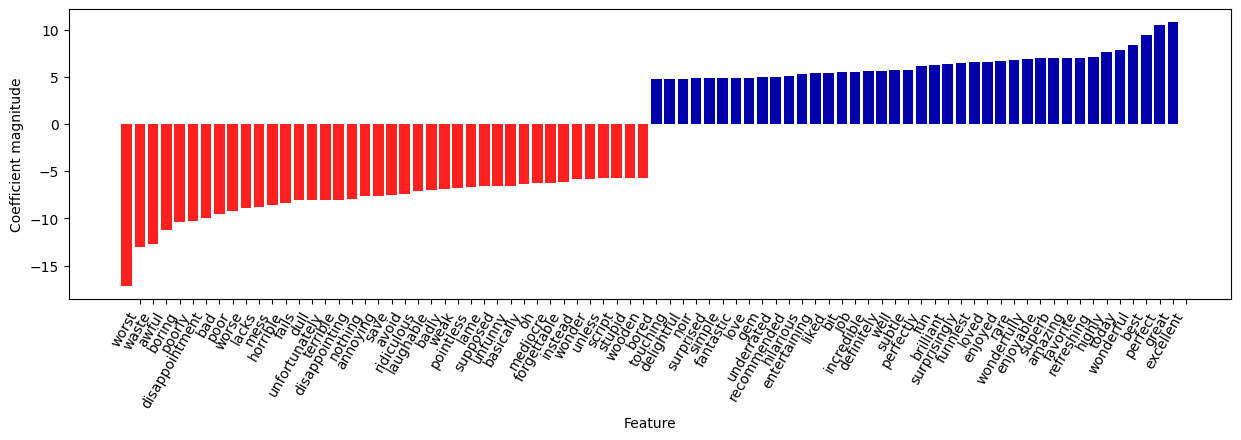

In [25]:
# ===== 书 7.6 节：可视化模型系数 =====
mglearn.tools.visualize_coefficients(
    grid.best_estimator_.named_steps["logisticregression"].coef_,
    feature_names, n_top_features=40)

## 7.7 多个单词的词袋（n 元分词）

使用词袋表示的主要缺点之一是**完全舍弃了单词顺序**。因此，"it's bad, not good at all"（电影很差，一点也不好）和 "it's good, not bad at all"（电影很好，还不错）这两个字符串的词袋表示**完全相同**，尽管它们的含义相反。将 "not"（不）放在单词前面，这只是上下文很重要的一个例子（可能是一个极端的例子）。

In [26]:
# ===== 书 7.7 节：ngram_range 玩具示例 =====
print("bards_words:\n{}".format(bards_words))

bards_words:
['The fool doth think he is wise,', 'but the wise man knows himself to be a fool']


In [27]:
# ===== 书 7.7 节：ngram_range=(1, 1) =====
cv = CountVectorizer(ngram_range=(1, 1)).fit(bards_words)
print("Vocabulary size: {}".format(len(cv.vocabulary_)))
print("Vocabulary:\n{}".format(cv.get_feature_names_out()))  # 版本适配：get_feature_names 已改名 get_feature_names_out

Vocabulary size: 13
Vocabulary:
['be' 'but' 'doth' 'fool' 'he' 'himself' 'is' 'knows' 'man' 'the' 'think'
 'to' 'wise']


In [28]:
# ===== 书 7.7 节：ngram_range=(2, 2) =====
cv = CountVectorizer(ngram_range=(2, 2)).fit(bards_words)
print("Vocabulary size: {}".format(len(cv.vocabulary_)))
print("Vocabulary:\n{}".format(cv.get_feature_names_out()))  # 版本适配：get_feature_names 已改名 get_feature_names_out

Vocabulary size: 14
Vocabulary:
['be fool' 'but the' 'doth think' 'fool doth' 'he is' 'himself to'
 'is wise' 'knows himself' 'man knows' 'the fool' 'the wise' 'think he'
 'to be' 'wise man']


In [29]:
# ===== 书 7.7 节：二元分词的密集表示 =====
print("Transformed data (dense):\n{}".format(cv.transform(bards_words).toarray()))

Transformed data (dense):
[[0 0 1 1 1 0 1 0 0 1 0 1 0 0]
 [1 1 0 0 0 1 0 1 1 0 1 0 1 1]]


In [30]:
# ===== 书 7.7 节：ngram_range=(1, 3) =====
cv = CountVectorizer(ngram_range=(1, 3)).fit(bards_words)
print("Vocabulary size: {}".format(len(cv.vocabulary_)))
print("Vocabulary:\n{}".format(cv.get_feature_names_out()))  # 版本适配：get_feature_names 已改名 get_feature_names_out

Vocabulary size: 39
Vocabulary:
['be' 'be fool' 'but' 'but the' 'but the wise' 'doth' 'doth think'
 'doth think he' 'fool' 'fool doth' 'fool doth think' 'he' 'he is'
 'he is wise' 'himself' 'himself to' 'himself to be' 'is' 'is wise'
 'knows' 'knows himself' 'knows himself to' 'man' 'man knows'
 'man knows himself' 'the' 'the fool' 'the fool doth' 'the wise'
 'the wise man' 'think' 'think he' 'think he is' 'to' 'to be' 'to be fool'
 'wise' 'wise man' 'wise man knows']


In [31]:
# ===== 书 7.7 节：IMDb 上的 n 元分词网格搜索 =====
pipe = make_pipeline(TfidfVectorizer(min_df=5), LogisticRegression())
# 运行网格搜索需要很长时间，因为网格相对较大，且包含三元分词
param_grid = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
              "tfidfvectorizer__ngram_range": [(1, 1), (1, 2), (1, 3)]}

grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(text_train, y_train)
print("Best cross-validation score: {:.2f}".format(grid.best_score_))
print("Best parameters:\n{}".format(grid.best_params_))

Best cross-validation score: 0.91
Best parameters:
{'logisticregression__C': 100, 'tfidfvectorizer__ngram_range': (1, 3)}


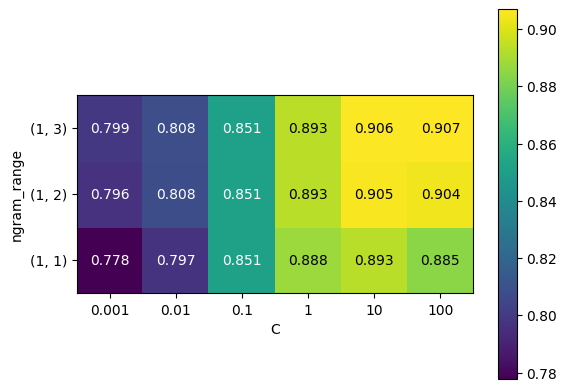

In [32]:
# ===== 书 7.7 节：交叉验证分数热图 =====
# 从网格搜索中提取分数
scores = grid.cv_results_['mean_test_score'].reshape(-1, 3).T

# 热图可视化
heatmap = mglearn.tools.heatmap(
    scores, xlabel="C", ylabel="ngram_range", cmap="viridis", fmt="%.3f",
    xticklabels=param_grid['logisticregression__C'],
    yticklabels=param_grid['tfidfvectorizer__ngram_range'])
plt.colorbar(heatmap)

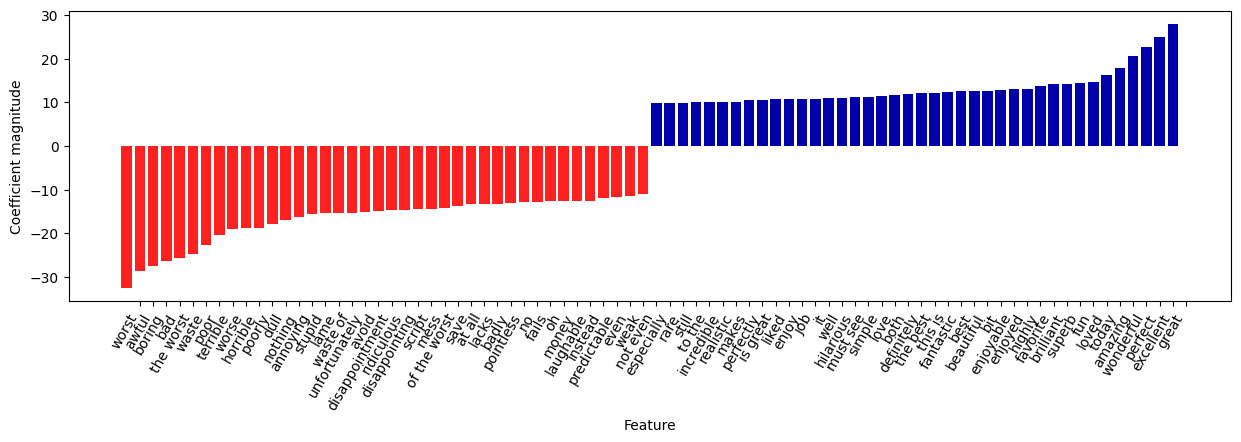

In [33]:
# ===== 书 7.7 节：最佳模型的重要系数 =====
# 提取特征名称与系数
vect = grid.best_estimator_.named_steps['tfidfvectorizer']
feature_names = np.array(vect.get_feature_names_out())  # 版本适配：get_feature_names 已改名 get_feature_names_out
coef = grid.best_estimator_.named_steps['logisticregression'].coef_
mglearn.tools.visualize_coefficients(coef, feature_names, n_top_features=40)

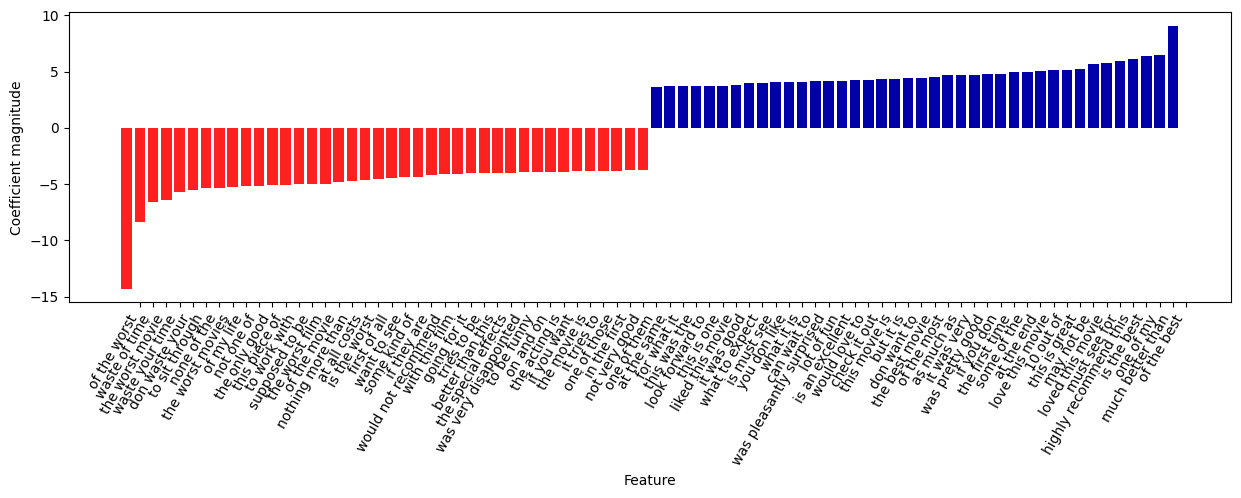

In [34]:
# ===== 书 7.7 节：只看三元分词特征 =====
# 找到三元分词特征
mask = np.array([len(feature.split(" ")) for feature in feature_names]) == 3
# 仅将三元分词特征可视化
mglearn.tools.visualize_coefficients(coef.ravel()[mask],
                                     feature_names[mask], n_top_features=40)

## 7.8 高级分词、词干提取与词形还原

如前所述，CountVectorizer 和 TfidfVectorizer 中的特征提取相对简单，还有更为复杂的方法。在更加复杂的文本处理应用中，通常需要改进的步骤是词袋模型的第一步：**分词（tokenization）**——这一步骤为特征提取定义了一个单词是如何构成的。

In [35]:
# ===== 书 7.8 节：对比词形还原与词干提取 =====
import spacy
import nltk

# 加载spacy的英语模型
en_nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])  # 版本适配：spacy 1.x 模型名 'en' 已停用（需先 python -m spacy download en_core_web_sm）
# 将nltk的Porter词干提取器实例化
stemmer = nltk.stem.PorterStemmer()

# 定义一个函数来对比spacy中的词形还原与nltk中的词干提取
def compare_normalization(doc):
    # 在spacy中对文档进行分词
    doc_spacy = en_nlp(doc)
    # 打印出spacy找到的词元
    print("Lemmatization:")
    print([token.lemma_ for token in doc_spacy])
    # 打印出Porter词干提取器找到的词例
    print("Stemming:")
    print([stemmer.stem(token.norm_.lower()) for token in doc_spacy])

In [36]:
# ===== 书 7.8 节：同一个句子的两种标准化 =====
compare_normalization(u"Our meeting today was worse than yesterday, "
                      "I'm scared of meeting the clients tomorrow.")

Lemmatization:
['our', 'meeting', 'today', 'be', 'bad', 'than', 'yesterday', ',', 'I', 'be', 'scared', 'of', 'meet', 'the', 'client', 'tomorrow', '.']
Stemming:
['our', 'meet', 'today', 'wa', 'wors', 'than', 'yesterday', ',', 'i', 'am', 'scare', 'of', 'meet', 'the', 'client', 'tomorrow', '.']


In [37]:
# ===== 书 7.8 节：自定义分词器接入 CountVectorizer =====
# 技术细节：我们希望使用由CountVectorizer所使用的基于正则表达式的分词器，
# 并仅使用spacy的词形还原。
# 为此，我们将en_nlp.tokenizer（spacy分词器）替换为基于正则表达式的分词。
import re
# 在CountVectorizer中使用的正则表达式
regexp = re.compile('(?u)\\b\\w\\w+\\b')

# 加载spacy语言模型，并保存旧的分词器
en_nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])  # 版本适配：spacy 1.x 模型名 'en' 已停用（需先 python -m spacy download en_core_web_sm）
old_tokenizer = en_nlp.tokenizer
# 将分词器替换为前面的正则表达式
en_nlp.tokenizer = lambda string: spacy.tokens.Doc(  # 版本适配：tokens_from_list 已移除，改用 Doc 构造
    en_nlp.vocab, words=regexp.findall(string))

# 用spacy文档处理管道创建一个自定义分词器
# （现在使用我们自己的分词器）
def custom_tokenizer(document):
    doc_spacy = en_nlp(document)  # 版本适配：entity/parse 参数已移除（加载时已 disable）
    return [token.lemma_ for token in doc_spacy]

# 利用自定义分词器来定义一个计数向量器
lemma_vect = CountVectorizer(tokenizer=custom_tokenizer, min_df=5)

In [38]:
# ===== 书 7.8 节：词形还原后的词表大小 =====
# 利用带词形还原的CountVectorizer对text_train进行变换
X_train_lemma = lemma_vect.fit_transform(text_train)
print("X_train_lemma.shape: {}".format(X_train_lemma.shape))

# 标准的CountVectorizer，以供参考
vect = CountVectorizer(min_df=5).fit(text_train)
X_train = vect.transform(text_train)
print("X_train.shape: {}".format(X_train.shape))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


X_train_lemma.shape: (25000, 21581)


X_train.shape: (25000, 27271)


In [39]:
# ===== 书 7.8 节：只用 1% 训练数据对比 =====
# 仅使用1%的数据作为训练集来构建网格搜索
from sklearn.model_selection import StratifiedShuffleSplit

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10]}
cv = StratifiedShuffleSplit(n_splits=5, test_size=0.99,
                            train_size=0.01, random_state=0)
grid = GridSearchCV(LogisticRegression(), param_grid, cv=cv)
# 利用标准的CountVectorizer进行网格搜索
grid.fit(X_train, y_train)
print("Best cross-validation score "
      "(standard CountVectorizer): {:.3f}".format(grid.best_score_))
# 利用词形还原进行网格搜索
grid.fit(X_train_lemma, y_train)
print("Best cross-validation score "
      "(lemmatization): {:.3f}".format(grid.best_score_))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Best cross-validation score (standard CountVectorizer): 0.724


Best cross-validation score (lemmatization): 0.735


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 7.9 主题建模与文档聚类

常用于文本数据的一种特殊技术是**主题建模（topic modeling）**，这是描述"将每个文档分配给一个或多个主题（通常是无监督的）"这一任务的概括性术语。这方面一个很好的例子是新闻数据，它们可以被分为"政治""体育""金融"等主题。

In [40]:
# ===== 书 7.9 节：LDA 的输入预处理 =====
vect = CountVectorizer(max_features=10000, max_df=.15)
X = vect.fit_transform(text_train)

In [41]:
# ===== 书 7.9 节：训练 10 个主题的 LDA =====
from sklearn.decomposition import LatentDirichletAllocation
  # 版本适配：n_topics 参数已改名 n_components（sklearn 1.x 下旧名移除）
lda = LatentDirichletAllocation(n_components=10, learning_method="batch",
                                max_iter=25, random_state=0)
# 我们在一个步骤中构建模型并变换数据
# 计算变换需要花点时间，二者同时进行可以节省时间
document_topics = lda.fit_transform(X)

In [42]:
# ===== 书 7.9 节：components_ 形状 =====
lda.components_.shape

(10, 10000)

In [43]:
# ===== 书 7.9 节：整理并打印主题代表词 =====
# 对于每个主题（components_的一行），将特征排序（升序）
# 用[:, ::-1]将行反转，使排序变为降序
sorting = np.argsort(lda.components_, axis=1)[:, ::-1]
# 从向量器中获取特征名称
feature_names = np.array(vect.get_feature_names_out())  # 版本适配：get_feature_names 已改名 get_feature_names_out
# 打印出前10个主题
mglearn.tools.print_topics(topics=range(10), feature_names=feature_names,
                           sorting=sorting, topics_per_chunk=5, n_words=10)

topic 0       topic 1       topic 2       topic 3       topic 4       
--------      --------      --------      --------      --------      
family        music         comedy        war           worst         
father        musical       role          world         thing         
young         songs         cast          us            funny         
girl          dance         performance   american      didn          
mother        song          funny         our           nothing       
woman         role          actor         history       actually      
old           star          actors        documentary   want          
wife          action        played        own           10            
son           john          plays         real          horror        
home          cast          john          true          guy           


topic 5       topic 6       topic 7       topic 8       topic 9       
--------      --------      --------      --------      --------      
dire

In [44]:
# ===== 书 7.9 节：训练 100 个主题的 LDA =====
  # 版本适配：n_topics 参数已改名 n_components（sklearn 1.x 下旧名移除）
lda100 = LatentDirichletAllocation(n_components=100, learning_method="batch",
                                   max_iter=25, random_state=0)
document_topics100 = lda100.fit_transform(X)

In [45]:
# ===== 书 7.9 节：打印选中的 15 个主题 =====
topics = np.array([7, 16, 24, 25, 28, 36, 37, 41, 45, 51, 53, 54, 63, 89, 97])

sorting = np.argsort(lda100.components_, axis=1)[:, ::-1]
feature_names = np.array(vect.get_feature_names_out())  # 版本适配：get_feature_names 已改名 get_feature_names_out
mglearn.tools.print_topics(topics=topics, feature_names=feature_names,
                           sorting=sorting, topics_per_chunk=7, n_words=20)

topic 7       topic 16      topic 24      topic 25      topic 28      topic 36      topic 37      
--------      --------      --------      --------      --------      --------      --------      
prince        fi            victor        guy           york          french        miss          
minutes       sci           gary          gets          new           century       vote          
bat           monster       irish         bank          robert        jean          village       
brooks        effects       ireland       small         city          france        young         
mel           special       gray          straight      oliver        brando        old           
ladies        cgi           mafia         football      stanwyck      art           kevin         
world         creature      frankie       town          barbara       before        brazil        
fiction       channel       graham        london        lily          train         title         
leon      

In [46]:
# ===== 书 7.9 节：查看主题 45（music）权重最高的文档 =====
# 按主题45"music"进行排序
music = np.argsort(document_topics100[:, 45])[::-1]
# 打印出这个主题最重要的文档（每条只显示前两个句子）
for i in music[:10]:
    print(b".".join(text_train[i].split(b".")[:2]) + b".\n")

b'As drunken millionaire playboy Arthur Bach, Dudley Moore is perfect as a grown man trapped in childhood. As it turned out, the role fit Moore so perfectly, it trapped him as an actor as well.\n'
b"The Shining, you know what's weird about this movie? This is the movie that everyone, for people who claim to not like horror films, will always say that The Shining is a terrific film. This is Stanley Kubrick's classic vision of Stephen King's horror tale of madness and blood.\n"
b"Arthur Bach is decidedly unhappy in his life as a multi-millionaire and is attracted to people 'below him' in social standing - he pays for a hooker in the opening scenes and then is enormously attracted to a shoplifter.  He drinks quite a lot too, and sometimes he is driving while drinking, too, which of course is not funny, ever.\n"
b"Arthur Bach needs to grow up, but that is unfortunately not the only thing he needs to do. According to his extremely rich father, Arthur has to marry a certain wealthy Susan Joh

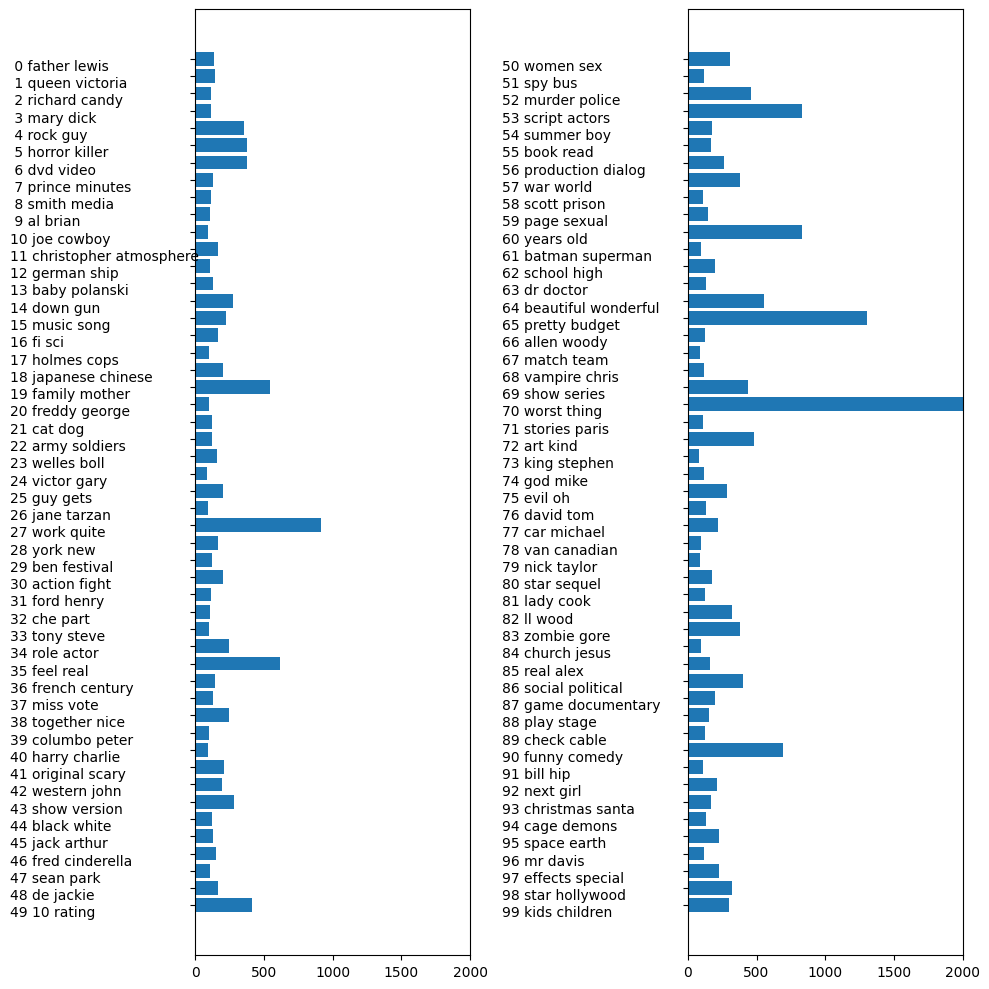

In [47]:
# ===== 书 7.9 节：100 个主题的整体权重 =====
fig, ax = plt.subplots(1, 2, figsize=(10, 10))
topic_names = ["{:>2} ".format(i) + " ".join(words)
               for i, words in enumerate(feature_names[sorting[:, :2]])]
# 两列的条形图：
for col in [0, 1]:
    start = col * 50
    end = (col + 1) * 50
    ax[col].barh(np.arange(50), np.sum(document_topics100, axis=0)[start:end])
    ax[col].set_yticks(np.arange(50))
    ax[col].set_yticklabels(topic_names[start:end], ha="left", va="top")
    ax[col].invert_yaxis()
    ax[col].set_xlim(0, 2000)
    yax = ax[col].get_yaxis()
    yax.set_tick_params(pad=130)
plt.tight_layout()

## 7.10 小结与展望

本章讨论了处理文本（也叫**自然语言处理，NLP**）的基础知识，还给出了一个对电影评论进行分类的示例应用。如果你想要尝试处理文本数据，那么这里讨论的工具应该是很好的出发点。特别是对于文本分类任务——比如检测垃圾邮件和欺诈或者情感分析——**词袋模型提供了一种简单而又强大的解决方案**。正如机器学习中常见的情况，**数据表示是 NLP 应用的关键**，检查所提取的词例和 n 元分词有助于深入理解建模过程。在文本处理应用中，对于监督任务与无监督任务而言，通常都可以用有意义的方式对模型进行**内省**（查看系数、查看主题），正如我们在本章所见——在实践中使用基于 NLP 的方法时，你应该充分利用这一能力。